# M12.5.4 — Reajuste de la cabeza de M11 en train: entrenamiento frente a cambio de entorno

Visualiza las salidas de `scripts/m12/m12_5_4_head_refit.py`. Protocolo: `docs/experiments/M12_5_4_head_refit_train.md`.
Solo lee las salidas del script y los npz de train/val; cal/test y X nunca se leen. Exploratorio: no apto para seleccionar modelo.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'paths.py').exists())
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
from scripts.m12.m12_5_3_posthoc_check import DATASET, LABELS, MIN_REGION_N, SNR_BINS, digest, npz_to_physical
from scripts.m12.m12_5_4_head_refit import MODELS, NPZ_NAMES, OUT_NAME

In [2]:
cfg = json.loads((ROOT/'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
RES = DATA_ROOT/'results'/DATASET
OUT = RES/OUT_NAME
NPZ = {s: RES/name for s, name in NPZ_NAMES.items()}
OUT, NPZ

(PosixPath('/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/M12_5_4_head_refit'),
 {'train': PosixPath('/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_train_predictions_embeddings.npz'),
  'val': PosixPath('/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_val_predictions_embeddings.npz')})

In [3]:
read = dict(dtype={'region': str})
summary = pd.read_csv(OUT/'summary.csv')
calib = pd.read_csv(OUT/'calib.csv', **read)
regions = pd.read_csv(OUT/'regions.csv', **read)
analysis = json.loads((OUT/'analysis.json').read_text())
with np.load(OUT/'head_refit_coefs.npz', allow_pickle=False) as a:
    hr_coef = a['coef']
    if a['label_names'].tolist() != LABELS:
        raise ValueError('Label order mismatch in head_refit_coefs.npz')
hr_coef.shape

(65, 3)

In [4]:
# Only pred/y are loaded (emb is not needed here); same unit handling as the script.
FY = {}
for s, path in NPZ.items():
    sha = digest(path)
    if sha != analysis['npz_sha256'][s]:
        raise ValueError(f'{s} npz SHA256 mismatch: {sha} != {analysis["npz_sha256"][s]}')
    with np.load(path, allow_pickle=False) as a:
        if a['label_names'].tolist() != LABELS:
            raise ValueError(f'{s}: label order mismatch')
        y, f, units = npz_to_physical(a[f'y_{s}'].astype(np.float64), a[f'pred_{s}'].astype(np.float64),
                                      a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64))
    if units != analysis['npz_label_units'][s]:
        raise ValueError(f'{s}: units differ from analysis.json')
    FY[s] = (f, y)
{s: FY[s][0].shape for s in FY}

{'train': (400000, 3), 'val': (40000, 3)}

## 0. Procedencia
Hashes de los dos npz y del script, filas por partición y entorno, comprobaciones superadas y ajustes registrados por el script.

In [5]:
script_sha_now = digest(ROOT/'scripts/m12/m12_5_4_head_refit.py')
for s in NPZ:
    print(f'{s:5s} npz      :', NPZ[s])
    print(f'{s:5s} SHA256   :', analysis['npz_sha256'][s], '(verified)')
print('script SHA256 :', analysis['script_sha256'],
      '(matches current file)' if script_sha_now == analysis['script_sha256'] else '(DIFFERS from current file)')
print('n_rows        :', analysis['n_rows'])
print('linear head   :', analysis['linear_head'])
print('head refit    :', analysis['head_refit'])
print('C3 alphas     :', analysis['c3']['alphas_selected'])
print('reproduction  :', analysis['reproduction'])
print('SNR           :', analysis['snr'])
print('settings      :', analysis['settings'])
pd.DataFrame(analysis['rows_per_environment']).rename_axis('environment')

train npz      : /data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_train_predictions_embeddings.npz
train SHA256   : a012a5a5cfb66bd636220635fcfc20f4ff07e143acca269f0a81545c78f5838b (verified)
val   npz      : /data/vserrano/cbc_pe_data/results/M11_final_G1_500k/m11_final_G1_500k_val_predictions_embeddings.npz
val   SHA256   : 586b95f2cb2cfaf150fbdd05760f50f47a95a555451fcb46d89492b7d00ed88b (verified)
script SHA256 : c71573baa57d7475c92d84c50b3c1ede013ff5d43e87a211e459837824d9d855 (matches current file)
n_rows        : {'train': 400000, 'val': 40000}
linear head   : {'max_abs_resid_std': {'train': 4.1212831769499303e-07, 'val': 3.167499436074195e-07}, 'design_rank': {'train': 65, 'val': 65}, 'max_abs_train_pred_from_val_head_std': {'chirp_mass': 4.133930642247208e-07, 'total_mass': 3.545360882650783e-07, 'chi_eff': 2.897463899920183e-07}}
head refit    : {'fit': 'per-label OLS theta ~ [h, 1], all train rows, no regularisation', 'design_rank': 65, 'n_params': 65}
C3

,train,val
environment,,
0,19714.0,NaN
2,19750.0,NaN
3,20142.0,NaN
4,20249.0,NaN
6,20163.0,NaN
9,20068.0,NaN
10,20079.0,NaN
11,20041.0,NaN
14,19666.0,NaN


In [6]:
pd.Series(analysis['checks_passed'], name='check_passed').to_frame()

,check_passed
0,val npz SHA256 equals pinned value
1,frozen G1 contract (g1_npe_contract.load_contr...
2,"train: npz shapes (n,3), emb (n,64)"
3,"train: label order [chirp_mass, total_mass, ch..."
4,train: npz split_path is the pinned split file
5,train: npz y_mean/y_std equal train-only label...
6,train: idx has no duplicates
7,train: idx equals train membership of split
8,train: all values finite
9,train: pred in units of y (|mean(pred) - mean(...


## 1. Decisiones
s_tr = pendiente global de θ sobre f de M11 en train; ganancias = ΔMSE/MSE_M11 en val (positivo favorece a HR/C3); R = mean(d_HR)/mean(d_C3); intervalos bootstrap pareados al 98,333 %. Decisión pre-registrada sobre estimaciones puntuales; `overfit_confound` es un indicador aparte.

In [7]:
cols = ['label', 's_tr', 's_val', 'mse_m11_train', 'mse_m11_val', 'mse_hr_train', 'mse_hr_val', 'mse_c3_val',
        'gain_rel_hr', 'gain_rel_hr_ci_lo', 'gain_rel_hr_ci_hi',
        'gain_rel_c3', 'gain_rel_c3_ci_lo', 'gain_rel_c3_ci_hi',
        'R', 'R_ci_lo', 'R_ci_hi', 'diff_c3_minus_hr', 'diff_c3_minus_hr_ci_lo', 'diff_c3_minus_hr_ci_hi',
        'c3_gain_positive', 'decision', 'overfit_confound']
summary[cols].set_index('label').T

label,chirp_mass,total_mass,chi_eff
s_tr,1.07118,1.072137,1.060296
s_val,1.050805,1.058501,1.037688
mse_m11_train,25.597558,81.46138,0.030471
mse_m11_val,33.958069,112.310568,0.037764
mse_hr_train,24.266485,75.124427,0.029604
mse_hr_val,33.464764,109.194688,0.037344
mse_c3_val,33.006127,107.601971,0.03713
gain_rel_hr,0.014527,0.027743,0.011116
gain_rel_hr_ci_lo,0.009439,0.021025,0.006798
gain_rel_hr_ci_hi,0.019675,0.034972,0.015442


## 2. F1 — Pendiente de θ sobre f de M11 por entorno, train frente a val
Un marcador por entorno (círculo = train, cuadrado = val) y líneas horizontales para la pendiente global de cada partición. Calibrado ⇒ pendiente ≈ 1.

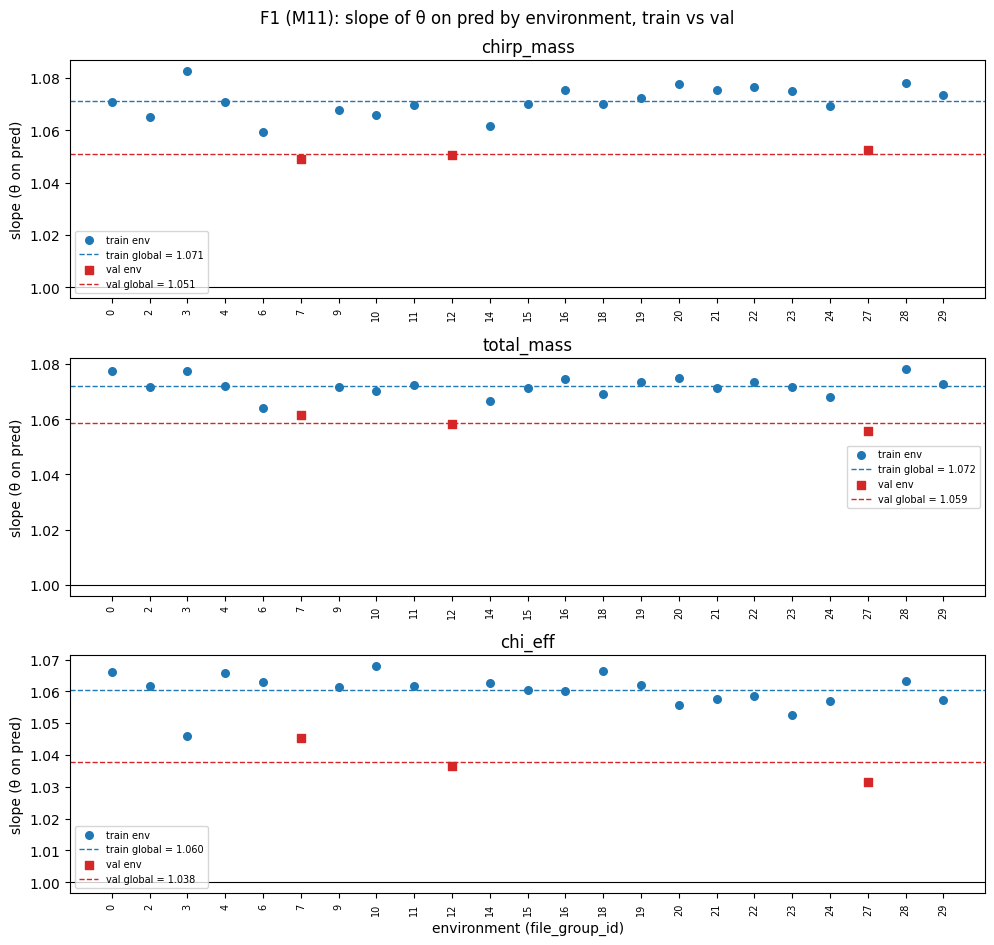

In [8]:
c = calib[calib.model == 'M11']
env_order = sorted(c.loc[c.region_type == 'environment', 'region'].unique(), key=lambda e: (len(e), e))
pos = {e: i for i, e in enumerate(env_order)}
fig, axes = plt.subplots(len(LABELS), 1, figsize=(max(6, 0.35 * len(env_order) + 2), 3.2 * len(LABELS)))
for ax, lab in zip(axes, LABELS):
    for split, mk, col in (('train', 'o', 'C0'), ('val', 's', 'C3')):
        e = c[(c.split == split) & (c.region_type == 'environment') & (c.label == lab)]
        ax.scatter(e.region.map(pos), e.slope_truth_on_pred, marker=mk, color=col, s=30, label=f'{split} env')
        g = c[(c.split == split) & (c.region_type == 'global') & (c.label == lab)].slope_truth_on_pred.iloc[0]
        ax.axhline(g, color=col, ls='--', lw=1, label=f'{split} global = {g:.3f}')
    ax.axhline(1, color='k', lw=0.8)
    ax.set_xticks(range(len(env_order)))
    ax.set_xticklabels(env_order, rotation=90, fontsize=7)
    ax.set_ylabel('slope (θ on pred)')
    ax.set_title(lab)
    ax.legend(fontsize=7)
axes[-1].set_xlabel('environment (file_group_id)')
fig.suptitle('F1 (M11): slope of θ on pred by environment, train vs val')
fig.tight_layout()
plt.show()

In [9]:
c[c.region_type == 'global'].pivot(index='split', columns='label',
    values=['slope_truth_on_pred', 'intercept_truth_on_pred', 'slope_pred_on_truth', 'r2', 'mse'])

slope_truth_on_pred                       intercept_truth_on_pred  \
label             chi_eff chirp_mass total_mass                 chi_eff   
split                                                                     
train            1.060296   1.071180   1.072137                0.004594   
val              1.037688   1.050805   1.058501                0.005559   

                            slope_pred_on_truth                        \
label chirp_mass total_mass             chi_eff chirp_mass total_mass   
split                                                                   
train  -2.833404  -7.195233            0.797610   0.849706   0.873668   
val    -1.981374  -5.949567            0.776008   0.835143   0.859322   

             r2                             mse                         
label   chi_eff chirp_mass total_mass   chi_eff chirp_mass  total_mass  
split                                                                   
train  0.842872   0.906080   0.932366  0.030471  25.597558   81.461380  
val    0.804043   0.875498   0.906696  0.037764  33.958069  112.310568

## 3. F2 — Curvas E[θ | pred] de M11, train frente a val (desde los npz)
Media de θ en 20 bins equi-cuantiles de la predicción de cada partición; bandas ±2 errores estándar de la media del bin; diagonal = calibrado.

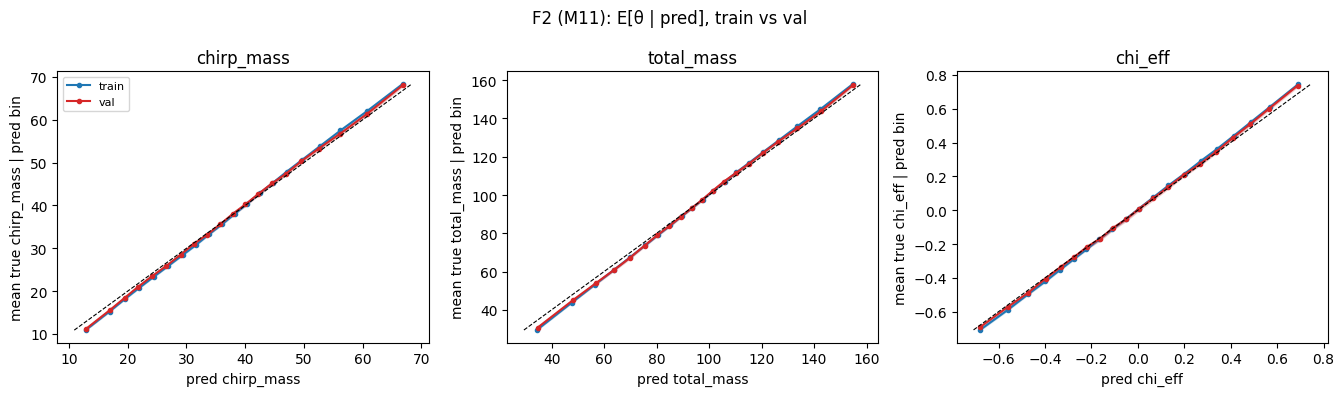

In [10]:
def binned_mean(x, t, nb=20):
    """Mean of t in nb equal-quantile bins of x; returns (mean x, mean t, 2*SE of mean t)."""
    edges = np.quantile(x, np.linspace(0, 1, nb + 1))
    b = np.clip(np.searchsorted(edges[1:-1], x, side='right'), 0, nb - 1)
    s = pd.DataFrame(dict(b=b, x=x, t=t)).groupby('b').agg(
        xm=('x', 'mean'), tm=('t', 'mean'), ts=('t', 'std'), n=('t', 'size'))
    return s.xm.values, s.tm.values, 2 * s.ts.values / np.sqrt(s.n.values)


fig, axes = plt.subplots(1, len(LABELS), figsize=(4.5 * len(LABELS), 4))
for j, (ax, lab) in enumerate(zip(axes, LABELS)):
    lims = []
    for split, col in (('train', 'C0'), ('val', 'C3')):
        f, y = FY[split]
        xm, tm, se2 = binned_mean(f[:, j], y[:, j])
        ax.plot(xm, tm, '-o', ms=3, color=col, label=split)
        ax.fill_between(xm, tm - se2, tm + se2, color=col, alpha=0.2)
        lims += [xm.min(), xm.max(), tm.min(), tm.max()]
    ax.plot([min(lims), max(lims)], [min(lims), max(lims)], 'k--', lw=0.8)
    ax.set_xlabel(f'pred {lab}')
    ax.set_ylabel(f'mean true {lab} | pred bin')
    ax.set_title(lab)
axes[0].legend(fontsize=8)
fig.suptitle('F2 (M11): E[θ | pred], train vs val')
fig.tight_layout()
plt.show()

## 4. F3 — Sesgo por decil con signo de la predicción de M11 (val): M11, HR y C3
Sesgo = media de θ − pred en cada decil de la predicción de M11 de esa misma etiqueta. Línea discontinua gris: M11 en train (deciles de la predicción de train). Cruces rojas = grupos sparse (n < 200).

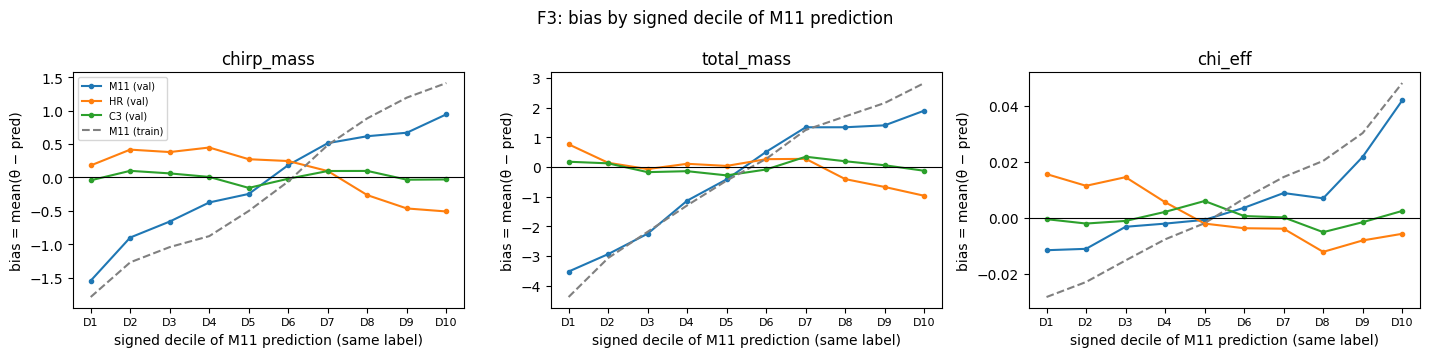

In [11]:
DECILES = [f'D{q}' for q in range(1, 11)]
fig, axes = plt.subplots(1, len(LABELS), figsize=(4.8 * len(LABELS), 3.6))
pos = np.arange(len(DECILES))
for ax, lab in zip(axes, LABELS):
    r = regions[(regions.region_type == f'pred_decile_{lab}') & (regions.label == lab)]
    for mdl in MODELS:
        rm = r[(r.split == 'val') & (r.model == mdl)].set_index('region').reindex(DECILES)
        ax.plot(pos, rm.bias, '-o', ms=3, label=f'{mdl} (val)')
        sp = rm['sparse'].astype(str).str.lower().eq('true').values
        ax.plot(pos[sp], rm.bias.values[sp], 'rx', ms=8)
    rt = r[(r.split == 'train') & (r.model == 'M11')].set_index('region').reindex(DECILES)
    ax.plot(pos, rt.bias, '--', color='0.5', label='M11 (train)')
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(pos)
    ax.set_xticklabels(DECILES, fontsize=8)
    ax.set_xlabel('signed decile of M11 prediction (same label)')
    ax.set_ylabel('bias = mean(θ − pred)')
    ax.set_title(lab)
axes[0].legend(fontsize=7)
fig.suptitle('F3: bias by signed decile of M11 prediction')
fig.tight_layout()
plt.show()

## 5. F4 — Ganancia relativa por decil y por SNR (val): HR frente a C3
(MSE_M11 − MSE_modelo)/MSE_M11 (%) por región con su intervalo bootstrap pareado al 98,333 % como banda. Descriptivo, sin control de multiplicidad entre regiones.

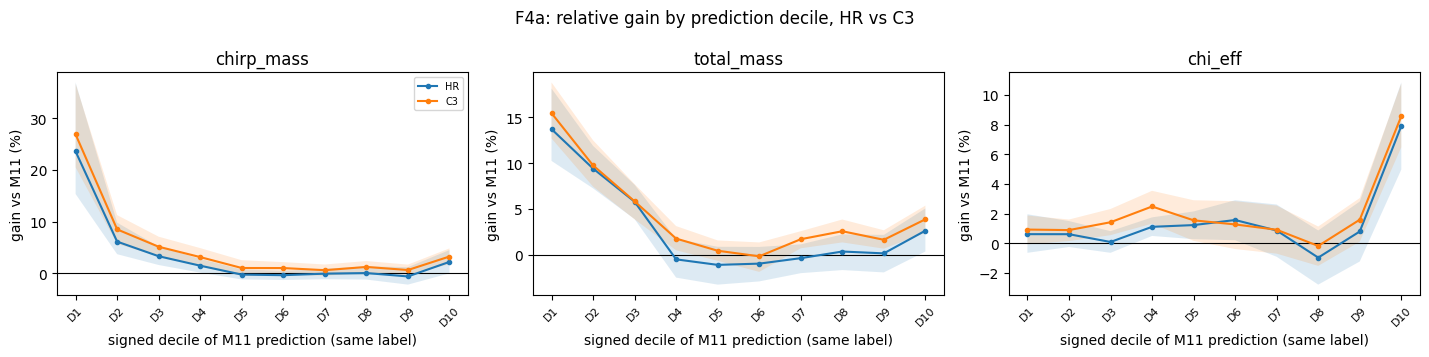

In [12]:
def plot_gain(region_type_of, order, xlabel, title):
    """region_type_of(label) -> region_type in regions.csv; order = x-axis region order."""
    fig, axes = plt.subplots(1, len(LABELS), figsize=(4.8 * len(LABELS), 3.6))
    pos = np.arange(len(order))
    for ax, lab in zip(axes, LABELS):
        r = regions[(regions.split == 'val') & (regions.region_type == region_type_of(lab)) & (regions.label == lab)]
        ax.axhline(0, color='k', lw=0.8)
        for mdl in ('HR', 'C3'):
            rm = r[r.model == mdl].set_index('region').reindex(order)
            ax.plot(pos, 100 * rm.gain_rel, '-o', ms=3, label=mdl)
            ax.fill_between(pos, 100 * rm.gain_rel_ci_lo, 100 * rm.gain_rel_ci_hi, alpha=0.15)
            sp = rm['sparse'].astype(str).str.lower().eq('true').values
            ax.plot(pos[sp], (100 * rm.gain_rel).values[sp], 'rx', ms=8)
        ax.set_xticks(pos)
        ax.set_xticklabels(order, rotation=45, fontsize=8)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('gain vs M11 (%)')
        ax.set_title(lab)
    axes[0].legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_gain(lambda lab: f'pred_decile_{lab}', DECILES, 'signed decile of M11 prediction (same label)',
          'F4a: relative gain by prediction decile, HR vs C3')

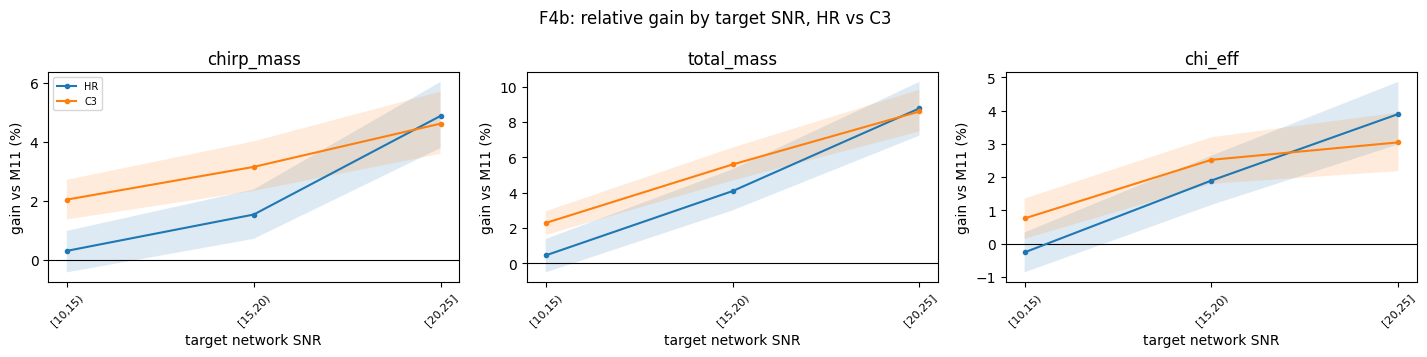

In [13]:
if analysis['snr']['available']:
    snr_order = [f'[{lo:g},{hi:g}' + (']' if closed else ')') for lo, hi, closed in SNR_BINS]
    plot_gain(lambda lab: 'target_snr', snr_order, 'target network SNR',
              'F4b: relative gain by target SNR, HR vs C3')
else:
    print('SNR not available:', analysis['snr'])

In [14]:
# Per-environment gains and fraction of the global gain (descriptive).
regions[(regions.split == 'val') & (regions.region_type == 'environment') & regions.model.isin(['HR', 'C3'])].pivot_table(
    index=['region', 'model'], columns='label', values=['n', 'gain_rel', 'gain_frac_of_global'])

gain_frac_of_global                        gain_rel             \
label                    chi_eff chirp_mass total_mass   chi_eff chirp_mass   
region model                                                                  
12     C3               0.421014   0.346676   0.341266  0.021117   0.029159   
       HR               0.409304   0.353188   0.350888  0.013599   0.015394   
27     C3               0.260239   0.293723   0.281316  0.012866   0.024302   
       HR               0.193854   0.385087   0.292406  0.006349   0.016510   
7      C3               0.318747   0.359601   0.377418  0.016407   0.030744   
       HR               0.396842   0.261725   0.356707  0.013532   0.011595   

                               n                        
label        total_mass  chi_eff chirp_mass total_mass  
region model                                            
12     C3      0.043165  13432.0    13432.0    13432.0  
       HR      0.029369  13432.0    13432.0    13432.0  
27     C3      0.035035  13426.0    13426.0    13426.0  
       HR      0.024098  13426.0    13426.0    13426.0  
7      C3      0.047675  13142.0    13142.0    13142.0  
       HR      0.029817  13142.0    13142.0    13142.0

## 6. Pendientes de HR frente a R² (val)
Pendiente OLS de la predicción sobre la verdad frente a R² = 1 − SSE/SST para M11 y HR (círculo = global, cruz = entorno); un estimador calibrado cumple pendiente ≈ R² (recta y = x) y pendiente de θ sobre pred ≈ 1.

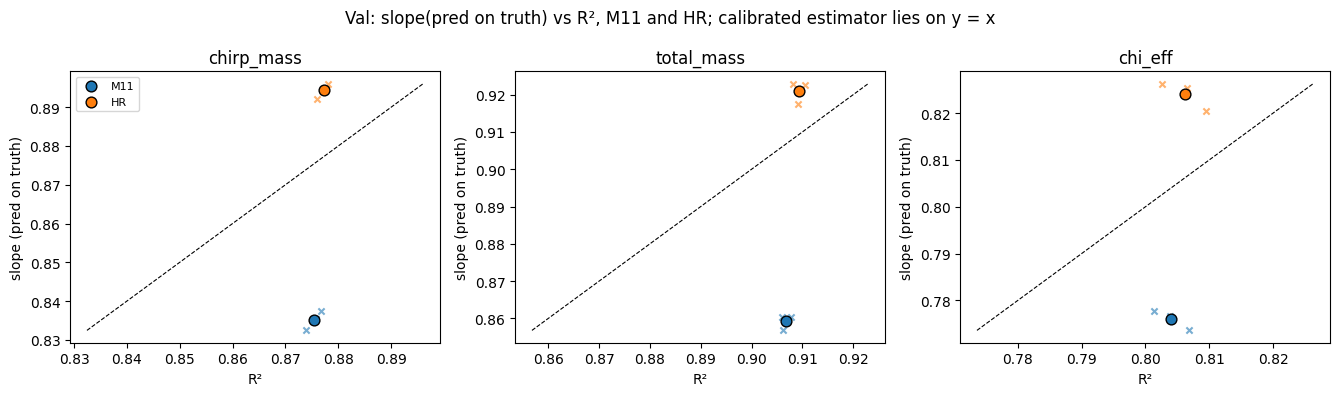

In [15]:
cv = calib[calib.split == 'val']
fig, axes = plt.subplots(1, len(LABELS), figsize=(4.5 * len(LABELS), 4))
for ax, lab in zip(axes, LABELS):
    s = cv[cv.label == lab]
    for mdl, col in (('M11', 'C0'), ('HR', 'C1')):
        g = s[(s.model == mdl) & (s.region_type == 'global')]
        e = s[(s.model == mdl) & (s.region_type == 'environment')]
        ax.scatter(e.r2, e.slope_pred_on_truth, marker='x', s=20, color=col, alpha=0.6)
        ax.scatter(g.r2, g.slope_pred_on_truth, marker='o', s=60, color=col, edgecolor='k', label=mdl)
    lim = [min(s.r2.min(), s.slope_pred_on_truth.min()), max(s.r2.max(), s.slope_pred_on_truth.max())]
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_xlabel('R²')
    ax.set_ylabel('slope (pred on truth)')
    ax.set_title(lab)
axes[0].legend(fontsize=8)
fig.suptitle('Val: slope(pred on truth) vs R², M11 and HR; calibrated estimator lies on y = x')
fig.tight_layout()
plt.show()

In [16]:
cv.pivot_table(index=['model', 'region_type', 'region'], columns='label',
               values=['slope_truth_on_pred', 'slope_pred_on_truth', 'r2', 'slope_minus_r2'])

r2                       slope_minus_r2  \
label                      chi_eff chirp_mass total_mass        chi_eff   
model region_type region                                                  
HR    environment 12      0.806504   0.877696   0.910553       0.018786   
                  27      0.802643   0.876025   0.908208       0.023630   
                  7       0.809490   0.878149   0.909041       0.010896   
      global      all     0.806222   0.877306   0.909284       0.017786   
M11   environment 12      0.803836   0.875783   0.907847      -0.027215   
                  27      0.801382   0.873944   0.905941      -0.023637   
                  7       0.806877   0.876720   0.906246      -0.033277   
      global      all     0.804043   0.875498   0.906696      -0.028035   

                                               slope_pred_on_truth             \
label                    chirp_mass total_mass             chi_eff chirp_mass   
model region_type region                                                        
HR    environment 12       0.017096   0.012012            0.825290   0.894792   
                  27       0.016215   0.014734            0.826273   0.892240   
                  7        0.017924   0.008324            0.820386   0.896073   
      global      all      0.017081   0.011764            0.824007   0.894387   
M11   environment 12      -0.040302  -0.047409            0.776621   0.835482   
                  27      -0.041513  -0.045452            0.777745   0.832431   
                  7       -0.039242  -0.049449            0.773600   0.837478   
      global      all     -0.040355  -0.047373            0.776008   0.835143   

                                    slope_truth_on_pred                        
label                    total_mass             chi_eff chirp_mass total_mass  
model region_type region                                                       
HR    environment 12       0.922565            0.977785   0.981326   0.987159  
                  27       0.922941            0.972198   0.982151   0.984288  
                  7        0.917366            0.986898   0.980431   0.991096  
      global      all      0.921049            0.978878   0.981286   0.987391  
M11   environment 12       0.860438            1.036628   1.050694   1.058389  
                  27       0.860489            1.031446   1.052599   1.055851  
                  7        0.856797            1.045186   1.049167   1.061638  
      global      all      0.859322            1.037688   1.050805   1.058501

## 7. Distribuciones y mapas de densidad: verdad frente a M11, HR y C3 (val)
Histogramas de θ y de cada predicción; tabla de anchuras (std(pred) frente a √(Var θ − MSE), la anchura de un estimador calibrado con ese MSE: cociente < 1 = comprimido, > 1 = estirado); mapas de densidad verdad–predicción con la diagonal, E[pred | verdad] (continua; pendiente R² incluso si es óptimo) y E[verdad | pred] (discontinua; sobre la diagonal si está calibrado). C3 se reconstruye con los α registrados y solo se usa si reproduce el MSE de `summary.csv`.

C3 reconstruido y verificado contra summary.csv (convención alpha·n: False )


std_true  std_pred  std_calibrated  ratio_pred_to_calibrated
label      model                                                              
chirp_mass M11     16.5152   14.7232         15.4529                    0.9528
           HR      16.5152   15.7669         15.4689                    1.0193
           C3      16.5152   15.4862         15.4837                    1.0002
total_mass M11     34.6944   31.2602         33.0362                    0.9462
           HR      34.6944   33.5086         33.0834                    1.0129
           C3      34.6944   33.1053         33.1074                    0.9999
chi_eff    M11      0.4390    0.3796          0.3936                    0.9644
           HR       0.4390    0.4028          0.3942                    1.0218
           C3       0.4390    0.3946          0.3944                    1.0004

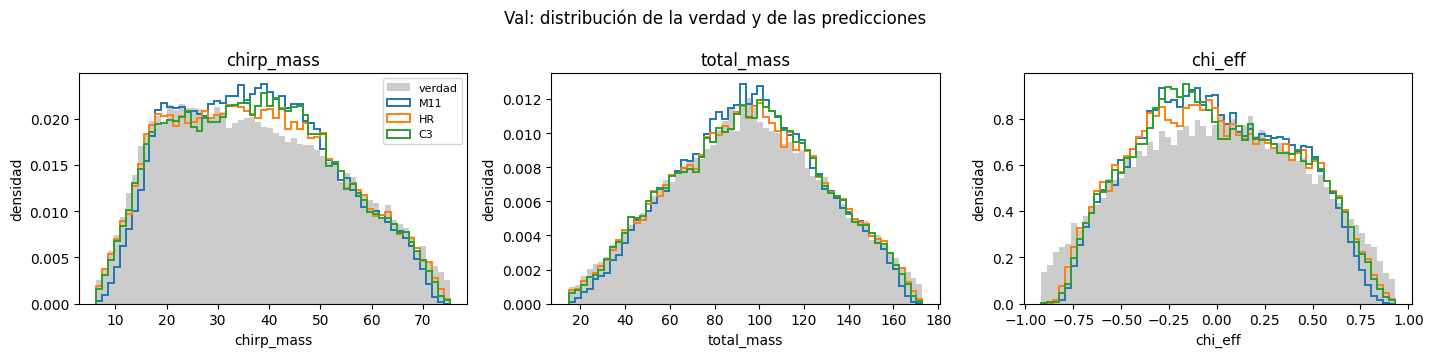

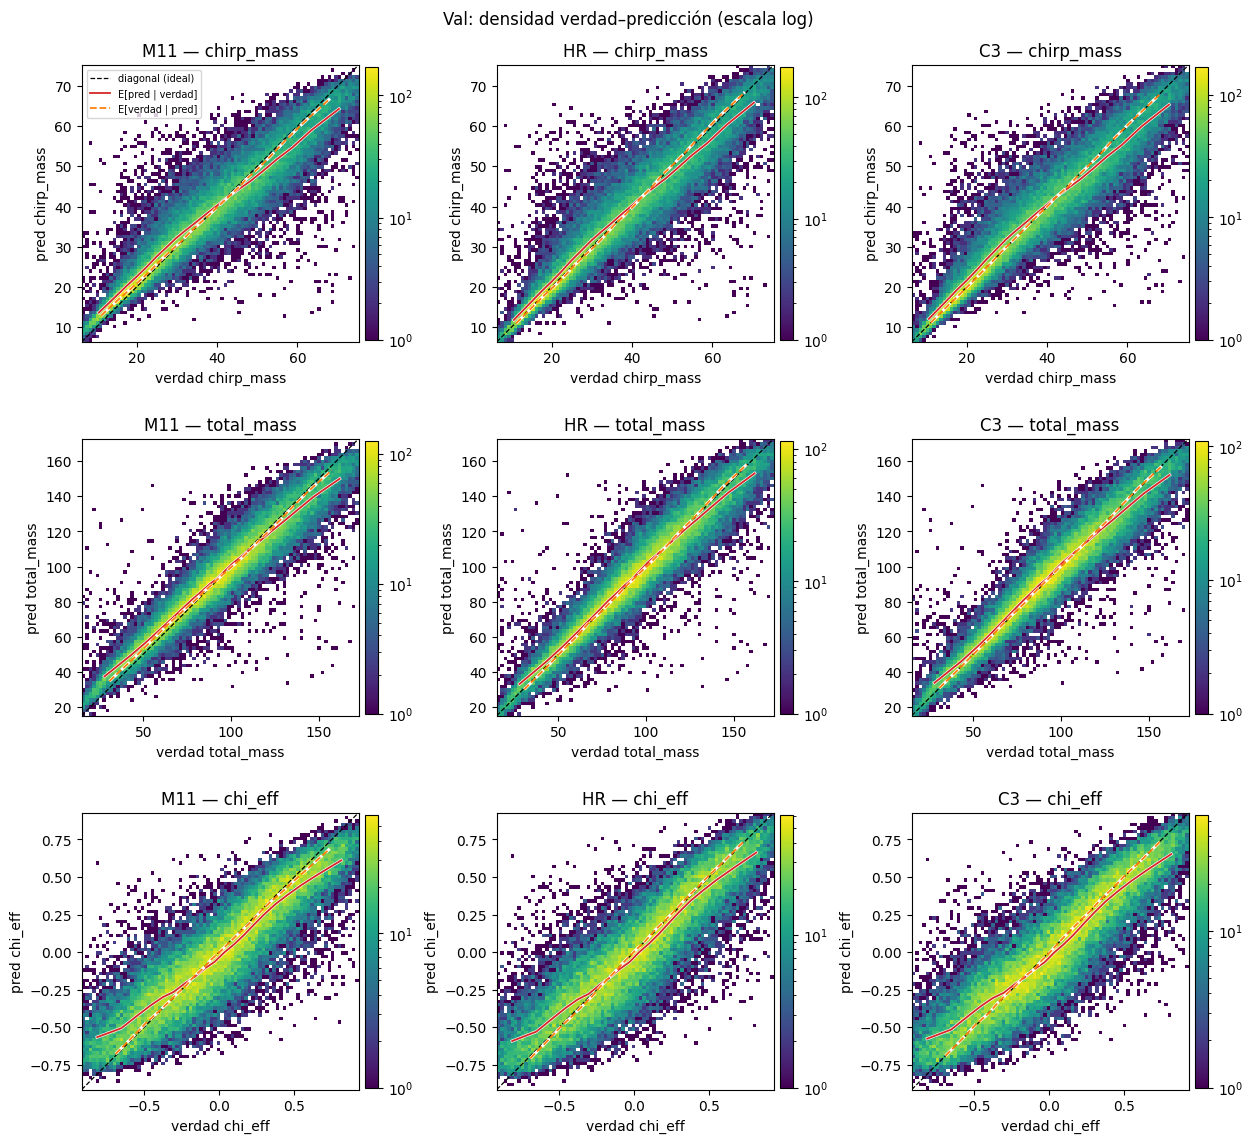

In [17]:
import h5py
from matplotlib.colors import LogNorm
from src.paths import resolve_processed_artifact

# --- datos de val en el orden de filas del npz ---
f_val, y_val = FY['val']
with np.load(NPZ['val'], allow_pickle=False) as a:
    h_val = a['emb_val'].astype(np.float64)
    idx_val = a['idx_val'].astype(np.int64)
H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET,
                                file_name=cfg['dataset']['dataset_file'])
with h5py.File(H5, 'r') as hf:
    env_val = hf['file_group_id'][:][idx_val].astype(str)

s = summary.set_index('label')
mse = lambda p, j: float(np.mean((y_val[:, j] - p[:, j]) ** 2))

# --- HR: coeficientes del script (fila 64 = intercepto, unidades físicas) ---
f_hr = np.c_[h_val, np.ones(len(h_val))] @ hr_coef
for j, lab in enumerate(LABELS):
    if not np.isclose(mse(f_hr, j), s.loc[lab, 'mse_hr_val'], rtol=1e-5):
        raise ValueError(f'HR no reproduce mse_hr_val en {lab}: {mse(f_hr, j)} vs {s.loc[lab, "mse_hr_val"]}')

# --- C3 fuera de pliegue reconstruido con los alphas registrados ---
def c3_oof(scale_alpha_by_n):
    out = np.empty_like(f_val)
    z = np.c_[h_val, f_val]
    for e in np.unique(env_val):
        te, tr = env_val == e, env_val != e
        mu, sd = z[tr].mean(0), z[tr].std(0)
        Ztr, Zte = (z[tr] - mu) / sd, (z[te] - mu) / sd
        G = Ztr.T @ Ztr
        for j, lab in enumerate(LABELS):
            r = y_val[tr, j] - f_val[tr, j]
            alpha = analysis['c3']['alphas_selected'][e][lab] * (tr.sum() if scale_alpha_by_n else 1.0)
            beta = np.linalg.solve(G + alpha * np.eye(G.shape[0]), Ztr.T @ (r - r.mean()))
            out[te, j] = f_val[te, j] + r.mean() + Zte @ beta
    return out

PRED = {'M11': f_val, 'HR': f_hr}
for conv in (False, True):
    cand = c3_oof(conv)
    if all(np.isclose(mse(cand, j), s.loc[lab, 'mse_c3_val'], rtol=1e-4) for j, lab in enumerate(LABELS)):
        PRED['C3'] = cand
        print('C3 reconstruido y verificado contra summary.csv (convención alpha·n:', conv, ')')
        break
else:
    print('AVISO: C3 no reproduce mse_c3_val con ninguna convención; se omite de las figuras.')

# --- tabla de anchuras ---
rows = []
for j, lab in enumerate(LABELS):
    var_t = y_val[:, j].var()
    for m, p in PRED.items():
        m_se = mse(p, j)
        sd_cal = np.sqrt(max(var_t - m_se, 0.0))
        rows.append(dict(label=lab, model=m, std_true=np.sqrt(var_t), std_pred=p[:, j].std(),
                         std_calibrated=sd_cal, ratio_pred_to_calibrated=p[:, j].std() / sd_cal))
display(pd.DataFrame(rows).set_index(['label', 'model']).round(4))

# --- histogramas superpuestos ---
fig, axes = plt.subplots(1, len(LABELS), figsize=(4.8 * len(LABELS), 3.6))
for j, (ax, lab) in enumerate(zip(axes, LABELS)):
    allv = np.concatenate([y_val[:, j]] + [p[:, j] for p in PRED.values()])
    bins = np.linspace(*np.quantile(allv, [0.001, 0.999]), 61)
    ax.hist(y_val[:, j], bins=bins, density=True, color='0.8', label='verdad')
    for m, p in PRED.items():
        ax.hist(p[:, j], bins=bins, density=True, histtype='step', lw=1.4, label=m)
    ax.set_title(lab)
    ax.set_xlabel(lab)
    ax.set_ylabel('densidad')
axes[0].legend(fontsize=8)
fig.suptitle('Val: distribución de la verdad y de las predicciones')
fig.tight_layout()
plt.show()

# --- mapas de densidad verdad (x) frente a predicción (y) ---
models = list(PRED)
fig, axes = plt.subplots(len(LABELS), len(models), figsize=(4.2 * len(models), 3.9 * len(LABELS)))
for j, lab in enumerate(LABELS):
    allv = np.concatenate([y_val[:, j]] + [p[:, j] for p in PRED.values()])
    lo, hi = np.quantile(allv, [0.001, 0.999])
    edges = np.linspace(lo, hi, 81)
    for k, m in enumerate(models):
        ax, p = axes[j, k], PRED[m][:, j]
        *_, im = ax.hist2d(y_val[:, j], p, bins=[edges, edges], norm=LogNorm(), cmin=1, cmap='viridis')
        ax.plot([lo, hi], [lo, hi], 'k--', lw=0.9, label='diagonal (ideal)')
        xm, tm, _ = binned_mean(y_val[:, j], p)        # E[pred | verdad]
        ax.plot(xm, tm, '-', color='w', lw=2.2)
        ax.plot(xm, tm, '-', color='C3', lw=1.3, label='E[pred | verdad]')
        xm, tm, _ = binned_mean(p, y_val[:, j])        # E[verdad | pred], dibujada como (verdad, pred)
        ax.plot(tm, xm, '--', color='w', lw=2.2)
        ax.plot(tm, xm, '--', color='C1', lw=1.3, label='E[verdad | pred]')
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect('equal')
        ax.set_xlabel(f'verdad {lab}')
        ax.set_ylabel(f'pred {lab}')
        ax.set_title(f'{m} — {lab}')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
axes[0, 0].legend(fontsize=7, loc='upper left')
fig.suptitle('Val: densidad verdad–predicción (escala log)')
fig.tight_layout()
plt.show()

## Conclusiones M12.5.4 — origen de la contracción excesiva de M11: reajuste de la cabeza en train (HR)

**Qué es HR.** M11 termina en una cabeza lineal f = A·h + a (h = embedding de 64 dimensiones; verificado: residuo ≤ 4·10⁻⁷ en train y val; rango de [h, 1] = 65). HR conserva toda la red y sustituye solo (A, a) por la solución de mínimos cuadrados ordinarios de θ_j sobre [h, 1], ajustada con las 400 000 filas de train y h calculado en modo evaluación (dropout apagado), sin regularización. HR no usa val ni cal. C3 (M12.5.3) es el mismo tipo de corrector lineal sobre h, pero ajustado en entornos de val (LOEO, ridge). Comparar HR con C3 aísla el efecto de ajustar la corrección en train en vez de en entornos nuevos.

**Pregunta.** ¿La contracción de más de M11 (pendiente de θ sobre f ≈ 1,05 en val) viene del entrenamiento (H1: dropout antes de h, weight decay de AdamW 3·10⁻⁴, parada temprana) o de un cambio entre los entornos de train y los de val (H2)?

**Integridad.** 28/28 comprobaciones superadas. M11 y C3 en val reproducen `risk.csv` de M12.5.3 hasta ~10⁻¹³. Misma cabeza en train y val (error ≤ 4·10⁻⁷ en el espacio de predicciones). npz de train SHA256 a012a5a5…f5838b; npz de val 586b95f2…d00ed88b; script c71573ba…24d9d855. Bootstrap pareado intra-entorno en val (2000 réplicas, seed 125401), intervalos al 98,33 % (Bonferroni 3).

### Resultados verificados
| | chirp_mass | total_mass | chi_eff |
|---|---|---|---|
| pendiente de θ sobre f, M11 **train** | 1,071 | 1,072 | 1,060 |
| pendiente de θ sobre f, M11 val | 1,051 | 1,059 | 1,038 |
| MSE M11 train / val | 25,60 / 33,96 | 81,46 / 112,31 | 0,0305 / 0,0378 |
| ganancia HR en val | 1,45 % [0,94–1,97] | 2,77 % [2,10–3,50] | 1,11 % [0,68–1,54] |
| ganancia C3 en val | 2,80 % [2,33–3,28] | 4,19 % [3,69–4,65] | 1,68 % [1,26–2,11] |
| R = HR/C3 | 0,52 [0,35–0,68] | 0,66 [0,51–0,81] | 0,66 [0,49–0,82] |
| pendiente de θ sobre f, HR val | 0,981 | 0,987 | 0,979 |
| pendiente(f sobre θ) − R², M11 → HR (val) | −0,040 → +0,017 | −0,047 → +0,012 | −0,028 → +0,018 |
| decisión fijada de antemano | MIXED | MIXED | MIXED |
| OVERFIT_CONFOUND (MSE_train < 0,9·MSE_val) | sí | sí | sí |

1. **La contracción de más existe dentro de train**, en los 20 entornos de train (pendientes 1,05–1,08). Una cabeza óptima por mínimos cuadrados para h en modo evaluación tendría pendiente exactamente 1 en sus propios datos de ajuste (ecuaciones normales: Cov(e, f) = 0). Por tanto **la cabeza de M11 no está en su óptimo para h en modo evaluación ni siquiera en train ⇒ hay una componente inducida por el entrenamiento (H1), verificada.** H2 queda descartada como explicación única. No se separan dropout, weight decay y parada temprana.
2. **HR mejora a M11 en val sin usar val** (intervalos sin el 0 en las tres etiquetas). Recupera entre el 52 % y el 66 % de la ganancia de C3. C3 sigue siendo significativamente mejor (intervalo de C3 − HR sin el 0). Respecto al margen del 1 % de M12.5.3, solo total_mass lo supera con todo el intervalo.
3. **HR sobrecorrige en val:** pendiente de θ sobre f de 0,98 y predicciones algo demasiado dispersas (pendiente(f sobre θ) − R² > 0). El sesgo por decil (F3) se invierte en signo y baja en magnitud (chirp D1: −1,55 → ≈ +0,2). M11 en train tiene más pendiente de sesgo que en val, así que el estiramiento óptimo en train es mayor que el que val necesita.
4. **Colas:** HR recupera casi toda la ganancia de C3 en los deciles extremos (chirp D1 ~23,5 % frente a ~27 %; total D1 ~13,7 % frente a ~15,5 %; χ_eff D10 ~7,9 % frente a ~8,6 %). La pérdida frente a C3 está en los deciles centrales (total D4–D9: HR ≈ 0 o ligeramente negativa).
5. **SNR:** con SNR [20,25], HR ≈ C3 (chirp 4,9 frente a 4,6 %; total 8,8 frente a 8,6 %; χ_eff 3,9 frente a 3,0 %). Con SNR [10,15), HR ≈ 0 (0,3 / 0,5 / −0,3 %) mientras C3 gana 0,8–2,3 %.

### Hipótesis (no verificadas)
- El exceso de estiramiento de HR en val viene de la diferencia entre train y val (MSE de train ~25 % menor): sobreajuste (h más informativo en train que fuera de muestra) y/o cambio de entorno. **No se puede separar con los datos actuales**: no hay datos de los entornos de train que la red no haya visto (los 29 entornos están repartidos sin solaparse entre particiones).
- El estiramiento óptimo depende de la información de cada evento (SNR): una corrección lineal global no puede ser óptima a la vez con SNR alta y baja. Refuerza H3 (M12.5.3: contracción poco adaptativa) y apunta a salidas distribucionales o heterocedásticas.
- Pesos relativos de dropout, weight decay y parada temprana en la componente H1: desconocidos (requeriría reentrenar).

### Limitaciones
- Exploratorio. Una sola semilla de M11. Val (3 entornos) se usó además para la parada temprana de M11.
- El bootstrap no incluye la variabilidad del ajuste de HR ni de C3, ni la variabilidad entre entornos.
- Regiones (deciles, SNR, entorno) descriptivas, sin control de multiplicidad.
- HR no está validado como modelo desplegable (requeriría test y recalibrar el Mondrian).

### Consecuencias
- La contracción de M11 tiene una parte artificial, causada por cómo se entrenó, que se puede corregir. No es solo la regresión a la media inevitable por falta de información.
- Corregirla con datos de train (HR) funciona en las colas y con SNR alta, pero estira de más con SNR baja. Corregirla con datos de entornos no vistos (C3/C1) es mejor, a costa de gastar datos.
- La dependencia con la SNR indica que una corrección única no basta: el nivel de contracción debería adaptarse a cada evento. Esto se lleva a la revisión de arquitectura y pérdida como requisito (objetivo 3: salida distribucional o heterocedástica).
- Regla de parada cumplida: una ejecución, sin variantes.